In [1]:
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kurtosis

# Load a normal signal (replace with your actual file path)
normal_data = sio.loadmat('normal_signal.mat')
normal_signal = normal_data['X097_DE_time'].flatten()[:2048]  # Take a window

# Load a faulty signal (e.g., inner race fault)
faulty_data = sio.loadmat('faulty_signal.mat')
faulty_signal = faulty_data['X105_DE_time'].flatten()[:2048]

def extract_features(signal):
    rms = np.sqrt(np.mean(signal**2))
    kurt = kurtosis(signal)
    return rms, kurt

rms_normal, kurt_normal = extract_features(normal_signal)
rms_faulty, kurt_faulty = extract_features(faulty_signal)

print(f"Normal Signal -> RMS: {rms_normal:.4f}, Kurtosis: {kurt_normal:.4f}")
print(f"Faulty Signal -> RMS: {rms_faulty:.4f}, Kurtosis: {kurt_faulty:.4f}")

# Plotting
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(normal_signal, label='Normal', color='green')
plt.title('Normal Bearing Vibration')
plt.subplot(1, 2, 2)
plt.plot(faulty_signal, label='Faulty', color='red')
plt.title('Faulty Bearing Vibration')
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'normal_signal.mat'

In [2]:
# Cell 1: Setup and Download
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kurtosis
import urllib.request
import os

# Define the file names based on the CWRU dataset structure
# Normal baseline: 97.mat (X097_DE_time)
# Inner race fault: 105.mat (X105_DE_time)
normal_file = '97.mat'
faulty_file = '105.mat'

# Download the files if they don't exist
if not os.path.exists(normal_file):
    print(f"Downloading {normal_file}...")
    urllib.request.urlretrieve('https://engineering.case.edu/sites/default/files/97.mat', normal_file)

if not os.path.exists(faulty_file):
    print(f"Downloading {faulty_file}...")
    urllib.request.urlretrieve('https://engineering.case.edu/sites/default/files/105.mat', faulty_file)

# Load the .mat files
print("Loading .mat files...")
normal_data = sio.loadmat(normal_file)
faulty_data = sio.loadmat(faulty_file)

# Print the keys to understand the structure
print("Keys in normal data:", [key for key in normal_data.keys() if not key.startswith('__')])
print("Keys in faulty data:", [key for key in faulty_data.keys() if not key.startswith('__')])

Loading .mat files...
Keys in normal data: ['X097_DE_time', 'X097_FE_time', 'X097RPM']
Keys in faulty data: ['X105_DE_time', 'X105_FE_time', 'X105_BA_time', 'X105RPM']


Normal Signal -> RMS: 0.0733, Kurtosis: -0.0458
Faulty Signal -> RMS: 0.2887, Kurtosis: 2.5088


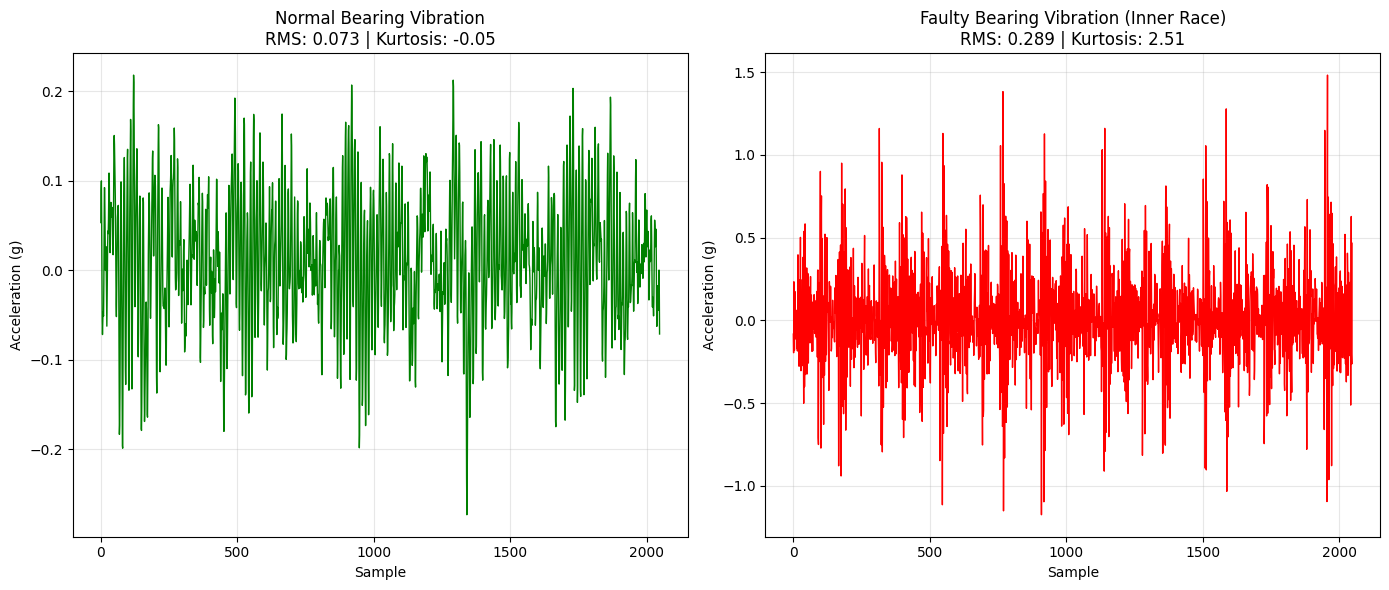

In [3]:
# Cell 2: Feature Extraction and Visualization
# Extract the drive-end (DE) time series data
# The keys typically look like 'X097_DE_time' for normal and 'X105_DE_time' for faulty
normal_signal = normal_data['X097_DE_time'].flatten()
faulty_signal = faulty_data['X105_DE_time'].flatten()

# Take a window of 2048 samples for analysis (standard practice)
window_size = 2048
normal_window = normal_signal[:window_size]
faulty_window = faulty_signal[:window_size]

def extract_features(signal):
    rms = np.sqrt(np.mean(signal**2))
    kurt = kurtosis(signal)
    return rms, kurt

rms_normal, kurt_normal = extract_features(normal_window)
rms_faulty, kurt_faulty = extract_features(faulty_window)

print(f"Normal Signal -> RMS: {rms_normal:.4f}, Kurtosis: {kurt_normal:.4f}")
print(f"Faulty Signal -> RMS: {rms_faulty:.4f}, Kurtosis: {kurt_faulty:.4f}")

# Plotting
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(normal_window, color='green', linewidth=1)
plt.title(f'Normal Bearing Vibration\nRMS: {rms_normal:.3f} | Kurtosis: {kurt_normal:.2f}')
plt.xlabel('Sample')
plt.ylabel('Acceleration (g)')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(faulty_window, color='red', linewidth=1)
plt.title(f'Faulty Bearing Vibration (Inner Race)\nRMS: {rms_faulty:.3f} | Kurtosis: {kurt_faulty:.2f}')
plt.xlabel('Sample')
plt.ylabel('Acceleration (g)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
import requests
import base64
import json
import getpass
import os

# --- CONFIGURATION ---
OWNER = "maashg3l4"
REPO = "legacy-asset-maintenance-copilot"
FILE_PATH = "01_data_exploration_cwru.ipynb" # The file you want to upload
COMMIT_MESSAGE = "feat: add Week 1 data exploration notebook"

# --- SECURE TOKEN INPUT ---
# This will prompt you to paste your token without showing it on screen
GITHUB_TOKEN = getpass.getpass("Please paste your GitHub Personal Access Token: ")

def sync_file_to_github(local_path, repo_path, message):
    """Uploads or updates a file in a GitHub repository via the REST API."""
    if not os.path.exists(local_path):
        print(f"❌ Error: Local file '{local_path}' not found.")
        return

    # Read local file content and encode to Base64 (required by GitHub API)
    with open(local_path, "rb") as f:
        content_bytes = f.read()
    content_base64 = base64.b64encode(content_bytes).decode("utf-8")

    api_url = f"https://api.github.com/repos/{OWNER}/{REPO}/contents/{repo_path}"
    headers = {
        "Authorization": f"Bearer {GITHUB_TOKEN}",
        "Accept": "application/vnd.github+json",
        "X-GitHub-Api-Version": "2022-11-28"
    }

    # Step 1: Check if the file already exists to get its SHA
    sha = None
    response = requests.get(api_url, headers=headers)
    if response.status_code == 200:
        file_info = response.json()
        sha = file_info["sha"]
        print(f"File already exists. Retrieved SHA: {sha}")
    elif response.status_code == 404:
        print("File does not exist. It will be created.")
    else:
        print(f"⚠️ Warning: Could not check file status. Status code: {response.status_code}")

    # Step 2: Prepare the payload
    payload = {
        "message": message,
        "content": content_base64
    }
    if sha:
        payload["sha"] = sha # Required for updates

    # Step 3: Send PUT request to create/update
    put_response = requests.put(api_url, headers=headers, data=json.dumps(payload))

    if put_response.status_code in [200, 201]:
        print(f"✅ Success! File '{repo_path}' has been synced to GitHub.")
        print(f"Commit SHA: {put_response.json()['commit']['sha']}")
    else:
        print(f"❌ Failed to sync file. Status: {put_response.status_code}")
        print(put_response.json())

# --- RUN THE SYNC ---
print("Starting GitHub sync...")
sync_file_to_github(FILE_PATH, FILE_PATH, COMMIT_MESSAGE)

Please paste your GitHub Personal Access Token: ··········
Starting GitHub sync...
❌ Error: Local file '01_data_exploration_cwru.ipynb' not found.


In [6]:
# Save the current notebook to the Colab environment
from google.colab import files
# This will download it to your browser, but we also want to save it locally
!jupyter nbconvert --to notebook --execute 01_data_exploration_cwru.ipynb --output 01_data_exploration_cwru.ipynb

[NbConvertApp] WARNING | pattern '01_data_exploration_cwru.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]


In [7]:
# Debugging Version
import requests
import base64
import json
import getpass
import os

OWNER = "maashg3l4"
REPO = "legacy-asset-maintenance-copilot"
FILE_PATH = "01_data_exploration_cwru.ipynb"

GITHUB_TOKEN = getpass.getpass("Paste Token: ")

def sync_file_to_github_debug(local_path, repo_path):
    if not os.path.exists(local_path):
        print(f"❌ FILE NOT FOUND: {local_path} does not exist in Colab files.")
        return

    with open(local_path, "rb") as f:
        content_base64 = base64.b64encode(f.read()).decode("utf-8")

    api_url = f"https://api.github.com/repos/{OWNER}/{REPO}/contents/{repo_path}"
    headers = {
        "Authorization": f"Bearer {GITHUB_TOKEN}",
        "Accept": "application/vnd.github+json",
    }

    # Check SHA
    response = requests.get(api_url, headers=headers)
    sha = response.json().get("sha") if response.status_code == 200 else None
    print(f"GET Status: {response.status_code} | SHA: {sha}")

    payload = {
        "message": "feat: add Week 1 data exploration notebook",
        "content": content_base64
    }
    if sha:
        payload["sha"] = sha

    put_response = requests.put(api_url, headers=headers, data=json.dumps(payload))

    if put_response.status_code in [200, 201]:
        print("✅ SUCCESS! Check your GitHub repo.")
    else:
        print(f"❌ FAILED. Status: {put_response.status_code}")
        print("Error Details:", put_response.json()) # THIS IS THE KEY

sync_file_to_github_debug(FILE_PATH, FILE_PATH)

Paste Token: ··········
❌ FILE NOT FOUND: 01_data_exploration_cwru.ipynb does not exist in Colab files.
